# Investigación reproducible · Gonzalo Landeira

Entrega de la sesión del 5 de noviembre de 2026. Este notebook cubre las preguntas,
el diseño, la extensión del pipeline, las baterías ejecutadas, las respuestas y las limitaciones.
Usa el kernel **PIIA2 - Gonzalo (MLflow)** y abre el notebook desde el clon.

Las tablas y conclusiones guardadas corresponden a ejecuciones reales. La ejecución
normal de este notebook actualiza el análisis de resultados guardados. Para ampliar
la batería activa los interruptores de la celda de ejecución.

## Preguntas, comparaciones y condiciones

| Dimensión | Comparación prevista | Evidencia y control |
|---|---|---|
| Dataset | Crédito, Telco, Framingham; LightGBM y TabPFN | Mismo YAML, semilla, test y métricas entre modelos |
| Tamaño | 10%, 50%, 100% del entrenamiento | Muestreo estratificado; test fijo |
| Semilla | 17, 42, 73 | Medias, desviaciones y diferencias pareadas |
| Preprocesamiento | Mediana/media; one-hot/ordinal | Ajuste exclusivo con train; una modificación por vez |
| Variables | Solo numéricas, categorías semánticas, +30 variables irrelevantes | Registrar columnas y dimensiones; semillas fijas |
| Hiperparámetros | Referencia y tres candidatos | Validación interna 20%; elegir por PR AUC; reajustar en train |
| Métricas | ROC AUC, PR AUC, F1, recall, precision, accuracy, balanced accuracy | Umbral 0.5; comparación con predictor mayoritario |
| Coste | Carga, preparación, entrenamiento, predicción y búsqueda | Segundos de pared y milisegundos de predicción por fila |
| Calidad | 10% de ausentes MCAR, 10% de etiquetas invertidas, balanceo | Perturbar solo train; control de igual tamaño para balanceo |
| Adicional: umbral | 0.5 frente a umbral de mejor F1 de validación | Test excluido de selección |
| Adicional: probabilidades | Brier por modelo y dataset | Menor es mejor; no confundir con calibración aislada |

Cada variante se repite en tres semillas y tres datasets. La batería completa tiene
126 ejecuciones por modelo (252 con ambos), más los ajustes internos de validación.
El cliente remoto de TabPFN consume la cuota de la cuenta. La extensión reutiliza
los componentes de `app/`; está en `investigacion_gonzalo/bateria.py`.

Las conclusiones por pregunta se generan con cifras de los resultados terminados.
Una condición pendiente o fallida no sirve para concluir que un modelo es peor.

In [1]:
from pathlib import Path
import sys
import os
from getpass import getpass
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "app" / "pipeline.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from investigacion_gonzalo.bateria import run_battery, SEEDS, DATASETS, VARIANTS
from investigacion_gonzalo.analisis import summarize

C:\Users\34698\OneDrive\Escritorio\PIIA2\TRABAJO_PIIAII\Modelos_Fundacionales\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/11 12:54:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\34698\OneDrive\Escritorio\PIIA2\TRABAJO_PIIAII\Modelos_Fundacionales\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Ejecutar o reanudar las baterías

Las ejecuciones terminadas se reutilizan si coinciden configuración, datos, código y
versiones. Los errores quedan registrados y se reintentan al volver a ejecutar.
Activa únicamente el modelo cuya batería quieras completar.
Para una primera prueba puedes pasar `datasets=["credit"], seeds=[42], variants=["baseline"]`
a `run_battery`. El plan completo utiliza los valores predeterminados.

**Alcance acordado:** usar solo TabPFN ya ejecutado. La bateria adicional de TabPFN queda pendiente; mantener `EJECUTAR_TABPFN = False`. Hay 126 ejecuciones de LightGBM y una de TabPFN en esta bateria, ademas de la evidencia historica separada.

In [2]:
EJECUTAR_LIGHTGBM = False
EJECUTAR_TABPFN = False

if EJECUTAR_LIGHTGBM:
    run_battery(models=["lightgbm"])
if EJECUTAR_TABPFN:
    if not os.environ.get("TABPFN_TOKEN"):
        os.environ["TABPFN_TOKEN"] = getpass("Token TabPFN (entrada oculta): ").strip()
    run_battery(models=["tabpfn"])

In [3]:
resultados = summarize()
display(resultados.groupby(["dataset", "model", "variant"]).agg(
    ejecuciones=("seed", "count"), pr_auc_media=("pr_auc", "mean"),
    pr_auc_sd=("pr_auc", "std"), f1_media=("f1", "mean"),
    segundos_media=("total_seconds", "mean")))

ejecuciones  pr_auc_media  \
dataset    model    variant                                           
credit     lightgbm balance_size_control            3      0.544843   
                    balanced_downsample             3      0.542625   
                    baseline                        3      0.555059   
                    label_noise                     3      0.547881   
                    mean_imputation                 3      0.555059   
                    medium_50pct                    3      0.544027   
                    missing_train                   3      0.554904   
                    noise_features                  3      0.550909   
                    numeric_only                    3      0.555059   
                    ordinal                         3      0.555059   
                    semantic_categories             3      0.554333   
                    small_10pct                     3      0.502082   
                    threshold_f1                    3      0.555059   
                    tuned                           3      0.557955   
           tabpfn   baseline                        3      0.569443   
                    medium_50pct                    3      0.566828   
                    small_10pct                     3      0.554307   
framingham lightgbm balance_size_control            3      0.250276   
                    balanced_downsample             3      0.260169   
                    baseline                        3      0.248965   
                    label_noise                     3      0.254809   
                    mean_imputation                 3      0.253158   
                    medium_50pct                    3      0.250014   
                    missing_train                   3      0.256753   
                    noise_features                  3      0.265091   
                    numeric_only                    3      0.248965   
                    ordinal                         3      0.248965   
                    semantic_categories             3      0.253893   
                    small_10pct                     3      0.227160   
                    threshold_f1                    3      0.248965   
                    tuned                           3      0.279418   
           tabpfn   baseline                        3      0.328356   
                    medium_50pct                    3      0.320154   
                    small_10pct                     3      0.287715   
telco      lightgbm balance_size_control            3      0.630852   
                    balanced_downsample             3      0.639224   
                    baseline                        3      0.654511   
                    label_noise                     3      0.629035   
                    mean_imputation                 3      0.653450   
                    medium_50pct                    3      0.632164   
                    missing_train                   3      0.649074   
                    noise_features                  3      0.640309   
                    numeric_only                    3      0.618586   
                    ordinal                         3      0.659227   
                    semantic_categories             3      0.654511   
                    small_10pct                     3      0.574625   
                    threshold_f1                    3      0.654511   
                    tuned                           3      0.670158   
           tabpfn   baseline                        3      0.675262   
                    medium_50pct                    3      0.670892   
                    small_10pct                     3      0.651901   

                                          pr_auc_sd  f1_media  segundos_media  
dataset    model    variant                                                    
credit     lightgbm balance_size_control   0.006662  0.459789        6.476353  
                    balanced_downsampl

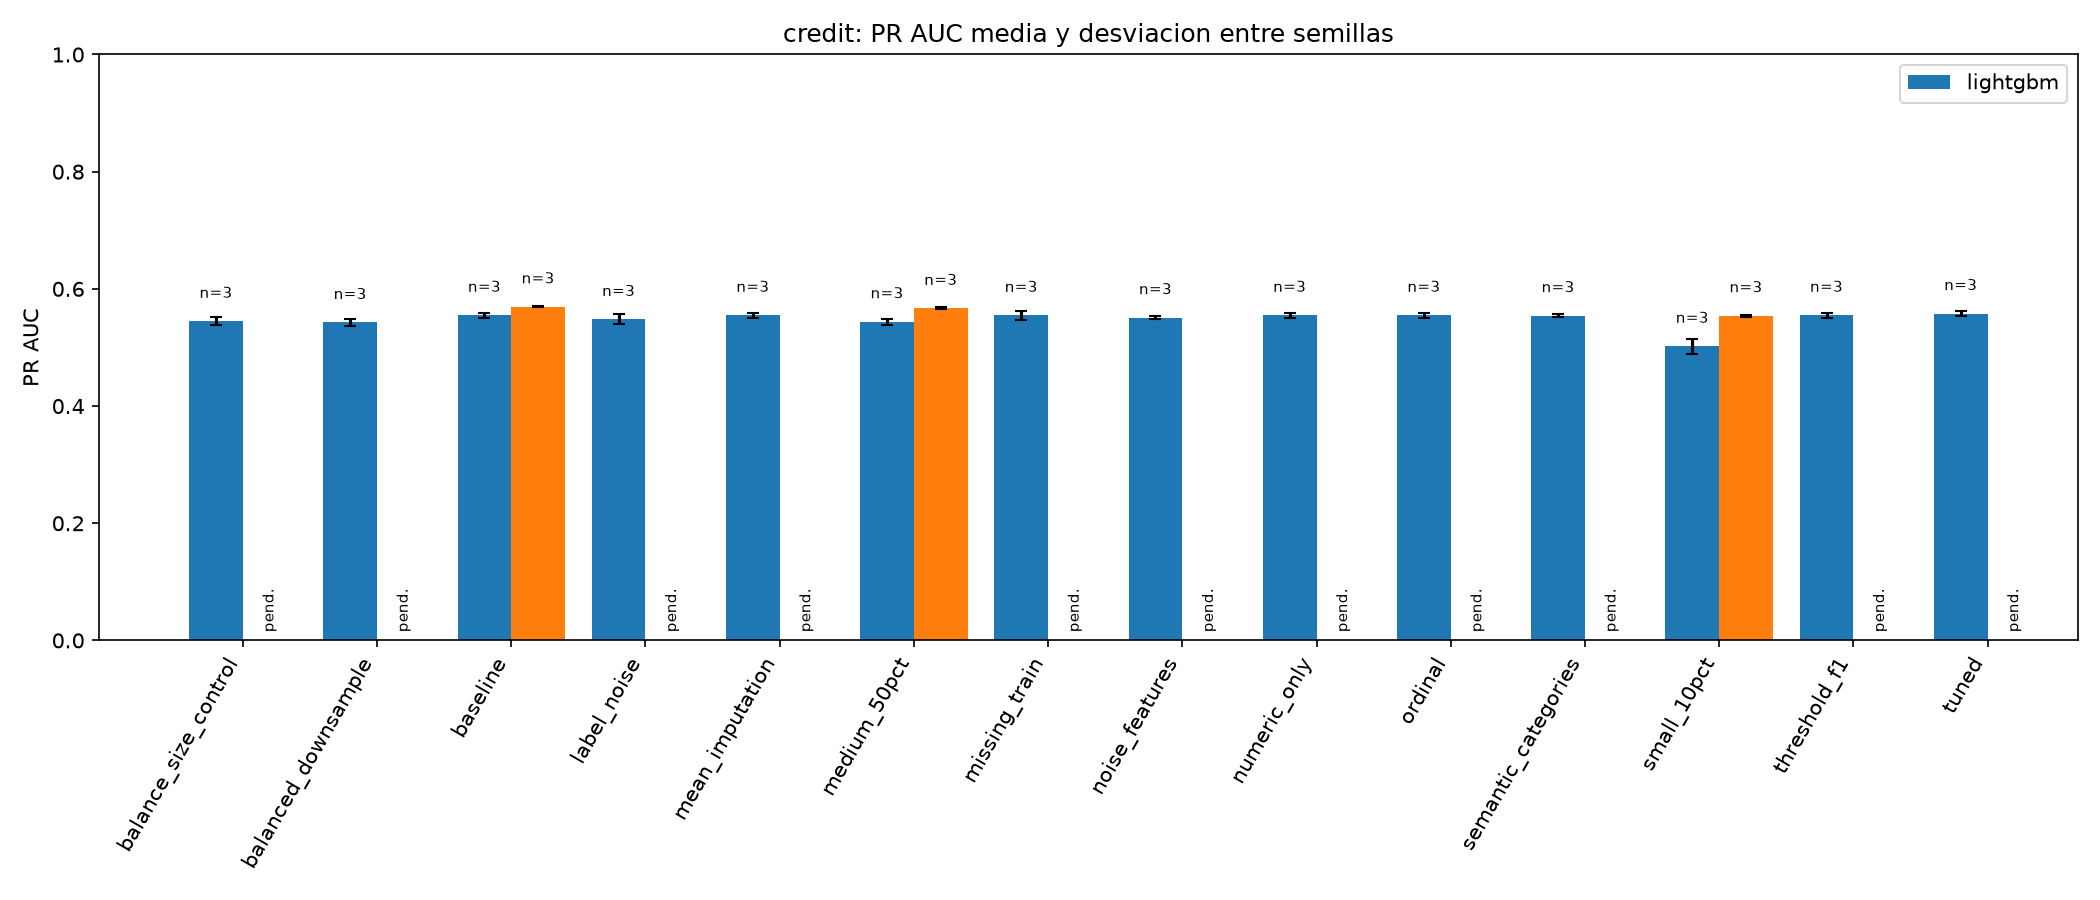

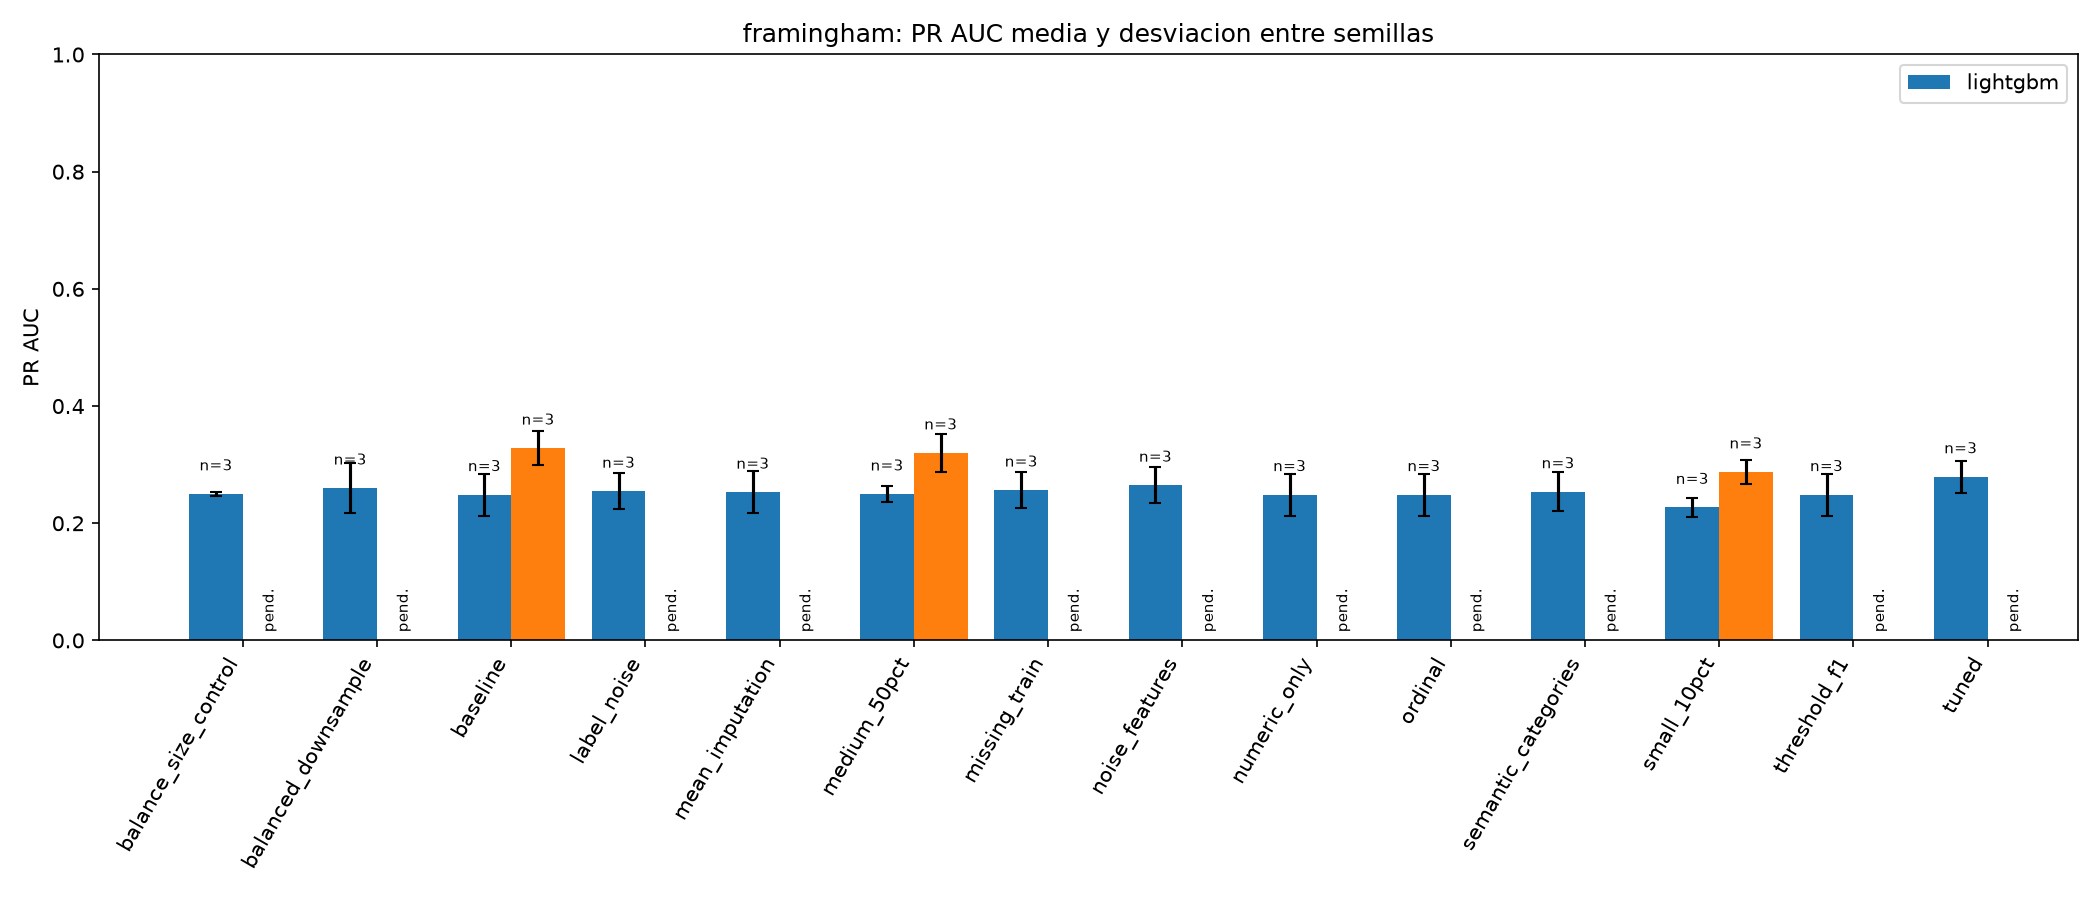

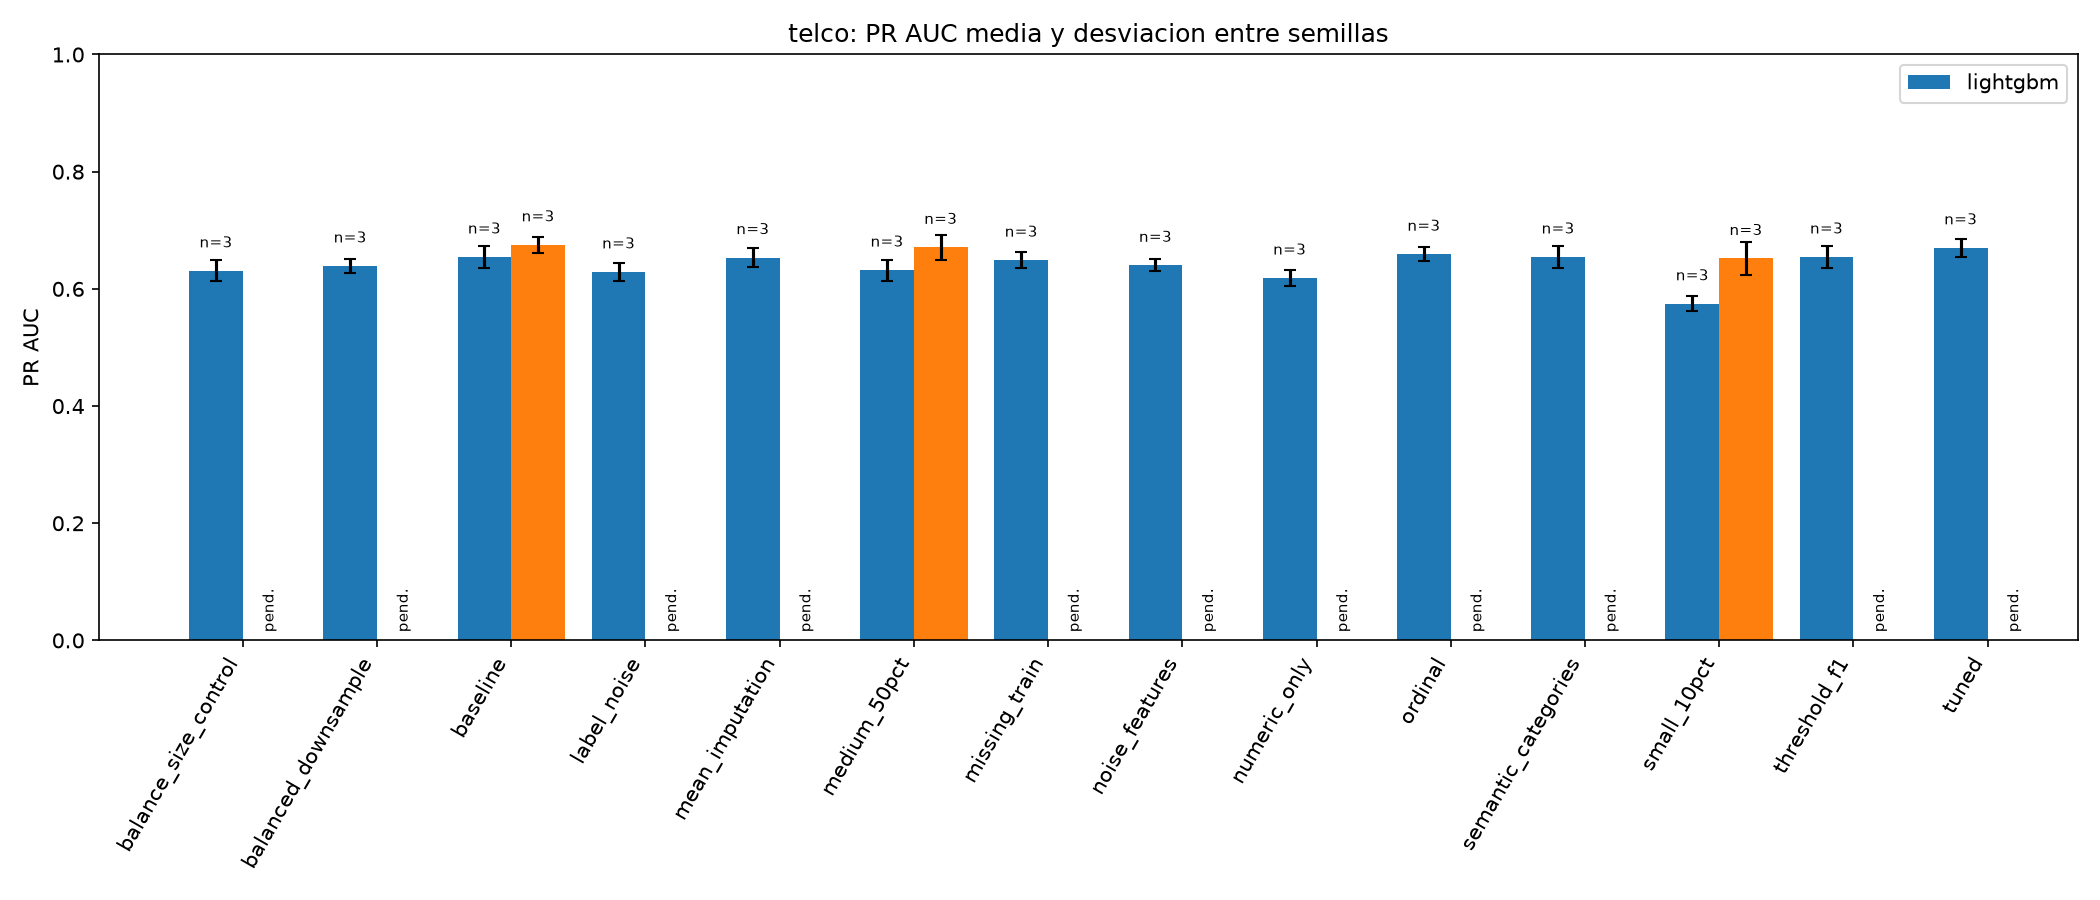

In [4]:
for archivo in sorted((ROOT / "investigacion_gonzalo" / "graficas").glob("*.png")):
    display(Image(filename=str(archivo)))

In [5]:
display(Markdown((ROOT / "investigacion_gonzalo" / "conclusiones.md").read_text(encoding="utf-8")))

# Investigación reproducible de Gonzalo Landeira

153 ejecuciones nuevas completadas. Semillas previstas: [17, 42, 73].

La batería reutiliza carga, preparación, partición, preprocesamiento, modelos y métricas de app. La extensión personal añade muestreo, perturbaciones, búsqueda interna y registro de condiciones. El código compartido permanece en el commit de referencia recogido en estado_git.txt.

## Diseño y controles

Test estratificado del YAML (20% en las configuraciones iniciales). Las fracciones de muestra se aplican solo al entrenamiento. El test se mantiene idéntico para cada dataset y semilla. Imputación y codificación se ajustan solo con entrenamiento. Ajustes de hiperparámetros y umbral usan una validación interna estratificada del 20% del entrenamiento. Tras elegirlos se reajusta con todo el entrenamiento y se evalúa una vez en test. Se conserva el valor de semilla del modelo.

Comparación de referencia: parámetros del YAML y umbral 0.5. El ajuste de parámetros evalúa tres candidatos, incluido el original, y elige por PR AUC de validación. Para LightGBM se varían num_leaves y n_estimators; para TabPFN n_estimators. El umbral se selecciona maximizando F1 de validación sobre una rejilla de 0.05 a 0.95. Son comparaciones exploratorias, con presupuestos acotados.

PR AUC usa el área trapezoidal de app.evaluation; no es Average Precision. Brier evalúa error de las probabilidades (menor es mejor), combinando discriminación y calibración.

## 1. Dataset: ¿se mantienen las conclusiones en los tres problemas?

| dataset | model | roc_auc | pr_auc | f1 | recall | precision | accuracy | balanced_accuracy | brier |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| credit | lightgbm | 0.7825 | 0.5551 | 0.4737 | 0.367 | 0.668 | 0.8197 | 0.6576 | 0.1345 |
| credit | tabpfn | 0.792 | 0.5694 | 0.4776 | 0.372 | 0.6672 | 0.8201 | 0.6597 | 0.1328 |
| framingham | lightgbm | 0.6391 | 0.249 | 0.129 | 0.0775 | 0.3845 | 0.8404 | 0.5274 | 0.1314 |
| framingham | tabpfn | 0.7175 | 0.3284 | 0.0959 | 0.0517 | 0.7222 | 0.8518 | 0.5235 | 0.1181 |
| telco | lightgbm | 0.8402 | 0.6545 | 0.5972 | 0.5481 | 0.6562 | 0.8039 | 0.7222 | 0.1379 |
| telco | tabpfn | 0.8537 | 0.6753 | 0.5906 | 0.5205 | 0.6829 | 0.8086 | 0.7166 | 0.1318 |

Las métricas se comparan entre modelos dentro de cada dataset. La prevalencia y la dificultad cambian entre datasets, por lo que un PR AUC mayor entre problemas no demuestra por sí solo superioridad.

## Cobertura real de la bateria

| dataset | model | ejecuciones |
| --- | --- | --- |
| credit | lightgbm | 42 |
| credit | tabpfn | 9 |
| framingham | lightgbm | 42 |
| framingham | tabpfn | 9 |
| telco | lightgbm | 42 |
| telco | tabpfn | 9 |

Plan por modelo: 126 ejecuciones. Cada combinacion dataset/variante requiere tres semillas. El archivo cobertura.csv permite identificar condiciones incompletas. La presencia de un modelo en la tabla no implica que haya completado todas las condiciones.

| dataset | seed | lightgbm | tabpfn | delta_tabpfn_menos_lightgbm |
| --- | --- | --- | --- | --- |
| credit | 17 | 0.5555 | 0.5682 | 0.0127 |
| credit | 42 | 0.5503 | 0.5701 | 0.0198 |
| credit | 73 | 0.5594 | 0.57 | 0.0106 |
| framingham | 17 | 0.271 | 0.3476 | 0.0766 |
| framingham | 42 | 0.2076 | 0.2957 | 0.0881 |
| framingham | 73 | 0.2683 | 0.3418 | 0.0736 |
| telco | 17 | 0.6735 | 0.6911 | 0.0175 |
| telco | 42 | 0.6361 | 0.6692 | 0.0331 |
| telco | 73 | 0.6539 | 0.6655 | 0.0116 |

Un delta positivo favorece TabPFN en PR AUC para esa partición; se revisa su consistencia entre semillas.

## 2. Tamaño de muestra

Se comparan 10%, 50% y 100% del entrenamiento; la referencia es el 100%. La selección es estratificada y usa la misma semilla para ambos modelos. Los tamaños absolutos se muestran porque las fracciones no representan el mismo número de filas entre datasets.

| dataset | model | variant | n_train | delta_pr_auc | delta_f1 | delta_recall | delta_precision | delta_brier |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| credit | lightgbm | medium_50pct | 12000.0 | -0.011 | -0.0124 | -0.0106 | -0.0138 | 0.0018 |
| credit | lightgbm | small_10pct | 2400.0 | -0.053 | -0.0355 | -0.0239 | -0.0611 | 0.0145 |
| credit | tabpfn | medium_50pct | 12000.0 | -0.0026 | -0.0108 | -0.0163 | 0.0123 | 0.0004 |
| credit | tabpfn | small_10pct | 2400.0 | -0.0151 | -0.0111 | -0.0128 | -0.0017 | 0.0028 |
| framingham | lightgbm | medium_50pct | 1696.0 | 0.001 | 0.005 | 0.0078 | -0.0686 | 0.0027 |
| framingham | lightgbm | small_10pct | 339.0 | -0.0218 | 0.0283 | 0.0284 | -0.0764 | 0.0137 |
| framingham | tabpfn | medium_50pct | 1696.0 | -0.0082 | -0.0252 | -0.0129 | -0.0556 | 0.0006 |
| framingham | tabpfn | small_10pct | 339.0 | -0.0406 | -0.0858 | -0.0465 | -0.2778 | 0.0028 |
| telco | lightgbm | medium_50pct | 2817.0 | -0.0223 | -0.0042 | -0.0027 | -0.0064 | 0.0042 |
| telco | lightgbm | small_10pct | 563.0 | -0.0799 | -0.0699 | -0.0615 | -0.0807 | 0.0307 |
| telco | tabpfn | medium_50pct | 2817.0 | -0.0044 | 0.0084 | 0.0143 | -0.0019 | 0.0008 |
| telco | tabpfn | small_10pct | 563.0 | -0.0234 | -0.0235 | -0.0241 | -0.0215 | 0.0049 |

credit, lightgbm, medium_50pct: cambio medio de PR AUC -0.0110, con 3 particiones y desviación de las diferencias 0.0078. Empeoramiento observado en esta batería.

credit, lightgbm, small_10pct: cambio medio de PR AUC -0.0530, con 3 particiones y desviación de las diferencias 0.0139. Empeoramiento observado en esta batería.

credit, tabpfn, medium_50pct: cambio medio de PR AUC -0.0026, con 3 particiones y desviación de las diferencias 0.0022. Empeoramiento observado en esta batería.

credit, tabpfn, small_10pct: cambio medio de PR AUC -0.0151, con 3 particiones y desviación de las diferencias 0.0005. Empeoramiento observado en esta batería.

framingham, lightgbm, medium_50pct: cambio medio de PR AUC +0.0010, con 3 particiones y desviación de las diferencias 0.0298. Mejora observada en esta batería.

framingham, lightgbm, small_10pct: cambio medio de PR AUC -0.0218, con 3 particiones y desviación de las diferencias 0.0332. Empeoramiento observado en esta batería.

framingham, tabpfn, medium_50pct: cambio medio de PR AUC -0.0082, con 3 particiones y desviación de las diferencias 0.0148. Empeoramiento observado en esta batería.

framingham, tabpfn, small_10pct: cambio medio de PR AUC -0.0406, con 3 particiones y desviación de las diferencias 0.0251. Empeoramiento observado en esta batería.

telco, lightgbm, medium_50pct: cambio medio de PR AUC -0.0223, con 3 particiones y desviación de las diferencias 0.0127. Empeoramiento observado en esta batería.

telco, lightgbm, small_10pct: cambio medio de PR AUC -0.0799, con 3 particiones y desviación de las diferencias 0.0204. Empeoramiento observado en esta batería.

telco, tabpfn, medium_50pct: cambio medio de PR AUC -0.0044, con 3 particiones y desviación de las diferencias 0.0105. Empeoramiento observado en esta batería.

telco, tabpfn, small_10pct: cambio medio de PR AUC -0.0234, con 3 particiones y desviación de las diferencias 0.0150. Empeoramiento observado en esta batería.

## 3. Semilla y estabilidad: cr?dito

Comparamos el PR AUC en las mismas diez semillas para ambos modelos.

| modelo | semillas | PR AUC m?nimo | PR AUC m?ximo | rango (m?x. ? m?n.) |
| --- | ---: | ---: | ---: | ---: |
| LightGBM | 10 | 0.5465 | 0.5789 | 0.0324 |
| TabPFN | 10 | 0.5557 | 0.5922 | 0.0365 |

En cr?dito, LightGBM vari? 0.5465?0.5789 (rango 0.0324) y TabPFN 0.5557?0.5922 (rango 0.0365). Los rangos se solapan ampliamente, as? que el valor de PR AUC depende de la semilla y esta comparaci?n no muestra un modelo consistentemente superior en las diez particiones. La variaci?n entre semillas fue parecida; TabPFN tuvo un rango algo mayor que LightGBM. Esta conclusi?n describe estas diez semillas y no garantiza el mismo resultado con otras particiones.

## 4. Preprocesamiento: minimo frente a avanzado

Comparamos dos niveles en credito, con LightGBM y TabPFN y las mismas tres semillas. El preprocesamiento minimo conserva las 23 columnas numericas tal como vienen; la tabla no contiene valores ausentes, asi que la imputacion no llega a intervenir. El avanzado interpreta SEX, EDUCATION y MARRIAGE como categorias y aplica one-hot, pasando de 23 a 33 columnas.

| Modelo | PR AUC minimo | PR AUC avanzado | Cambio medio | Cambios por semilla (minimo a maximo) | Cambio medio de F1 |
| --- | ---: | ---: | ---: | ---: | ---: |
| lightgbm | 0.5551 | 0.5543 | -0.00073 | -0.00339 a +0.00292 | -0.00036 |
| tabpfn | 0.5694 | 0.5697 | +0.00022 | -0.00076 a +0.00147 | -0.00323 |

Conclusion: en este dataset no se observa una mejora util por el preprocesamiento avanzado. En LightGBM el PR AUC medio bajo 0.00073; en TabPFN subio 0.00022. Ambos cambios son diminutos y las diferencias cambian de signo segun la semilla. F1 tampoco mejora de forma consistente. Para credito, el preprocesamiento minimo parece suficiente para estos dos modelos y estas particiones.

Esta prueba no demuestra que todo preprocesamiento sea innecesario: credito no tiene ausentes que imputar y solo se probo una transformacion avanzada de tres variables. La conclusion se limita a estas condiciones.
## 5. Tipos de variables, valores ausentes y dimensionalidad: crédito

Esta pregunta complementa el punto 4: allí se comparaba cuánto preprocesamiento aplicar; aquí observamos cómo responde el modelo a las características de los datos. Crédito tiene 23 columnas, todas numéricas y sin valores ausentes en la referencia. SEX, EDUCATION y MARRIAGE son códigos numéricos que pueden interpretarse como categorías; el efecto de esa interpretación ya se compara en el punto 4.

| Modelo | Cambio en los datos | Cambio medio de PR AUC | Rango entre tres semillas |
| --- | --- | ---: | ---: |
| LightGBM | 10% de valores ausentes | -0.00015 | -0.00290 a +0.00375 |
| LightGBM | 30 variables de ruido | -0.00415 | -0.00664 a -0.00283 |
| TabPFN | 10% de valores ausentes | -0.00217 | -0.00316 a -0.00054 |
| TabPFN | 30 variables de ruido | -0.00086 | -0.00162 a +0.00008 |

Para evaluar los valores ausentes, ocultamos al azar el 10% de las celdas de entrenamiento y dejamos limpio el test. El PR AUC apenas cambió: -0,00015 en LightGBM y -0,00217 en TabPFN. En TabPFN la bajada fue consistente en las tres semillas; en LightGBM el efecto cambió de signo. Otras métricas, como recall y precision, se movieron en direcciones distintas, así que no hay una mejora general. Esta prueba representa ausencias aleatorias, no todos los tipos de datos faltantes.

Para probar mayor dimensionalidad, añadimos 30 columnas aleatorias sin información (de 23 a 53). El PR AUC bajó en las tres semillas para LightGBM, con un cambio medio de -0,00415. Para TabPFN el cambio medio fue de -0,00086 y el rango incluye un resultado casi igual al de referencia. En este ensayo, LightGBM fue más afectado; ambos cambios son pequeños.

Conclusión: los datos de crédito son numéricos y completos, y no se observa que necesiten más tratamiento para las ausencias en esta prueba. Las variables categóricas codificadas y su tratamiento se explican en el punto 4. Añadir variables irrelevantes perjudicó ligeramente a ambos modelos, más a LightGBM. Son resultados de tres semillas y perturbaciones simuladas, por lo que describen solo estas condiciones.
## 6. Ajuste de hiperpar?metros: cr?dito

Para cada modelo comparamos la configuraci?n inicial con tres candidatos, seleccionados por PR AUC en una validaci?n interna. Despu?s se reajust? el modelo seleccionado con todos los datos de entrenamiento y se evalu? en el mismo test. Las tres semillas son emparejadas.

| Modelo | PR AUC inicial | PR AUC ajustado | Cambio medio | Cambio por semilla (m?nimo a m?ximo) | Cambio medio de F1 | B?squeda media | Tiempo total medio ajustado |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| lightgbm | 0.5551 | 0.5580 | +0.00290 | -0.00408 a +0.00653 | -0.00204 | 4.2 s | 12.3 s |
| tabpfn | 0.5694 | 0.5695 | +0.00007 | +0.00000 a +0.00022 | -0.00067 | 17.5 s | 26.6 s |

En LightGBM, el ajuste subio el PR AUC medio en 0,00290, pero el cambio fue desigual: mejoro 0,00653 y 0,00624 en dos semillas, y bajo 0,00408 en la tercera. El F1 medio bajo 0,00204. La busqueda tardo 4,2 segundos de media; contando el pipeline completo, cada ejecucion ajustada tardo 12,3 segundos de media.

En TabPFN, el PR AUC medio apenas cambio (+0,00007): en una semilla subio 0,00022 y en las otras dos quedo practicamente igual. El F1 medio bajo 0,00067. La busqueda tardo 17,5 segundos de media y el tiempo total fue 26,6 segundos por ejecucion ajustada.

Conclusion: para credito, la busqueda probada no aporta una mejora clara. LightGBM puede ganar algo en algunas particiones, pero no de forma estable y con una ligera bajada de F1; TabPFN practicamente no mejora. En ambos casos se paga tiempo adicional por probar candidatos. Con este presupuesto de tres candidatos, no parece compensar activar el ajuste si se prioriza tiempo y un resultado reproducible. Los tiempos remotos de TabPFN pueden variar por la red y el servicio; el coste de busqueda es una media de solo tres semillas.
## 7. ¿Cuentan todas las métricas la misma historia?

| dataset | model | accuracy | accuracy_majority | balanced_accuracy | pr_auc | f1 | recall | precision |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| credit | lightgbm | 0.8197 | 0.7788 | 0.6576 | 0.5551 | 0.4737 | 0.367 | 0.668 |
| credit | tabpfn | 0.8201 | 0.7788 | 0.6597 | 0.5694 | 0.4776 | 0.372 | 0.6672 |
| framingham | lightgbm | 0.8404 | 0.8479 | 0.5274 | 0.249 | 0.129 | 0.0775 | 0.3845 |
| framingham | tabpfn | 0.8518 | 0.8479 | 0.5235 | 0.3284 | 0.0959 | 0.0517 | 0.7222 |
| telco | lightgbm | 0.8039 | 0.7346 | 0.7222 | 0.6545 | 0.5972 | 0.5481 | 0.6562 |
| telco | tabpfn | 0.8086 | 0.7346 | 0.7166 | 0.6753 | 0.5906 | 0.5205 | 0.6829 |

accuracy_majority es la exactitud de predecir siempre la clase mayoritaria en ese test. Las diferencias de recall y precision permiten valorar falsos negativos y falsas alarmas. No se decide el mejor modelo por accuracy aislada ni se presupone que PR AUC y ROC AUC ordenen igual.

## 8. Coste de ejecución

| Dataset | Modelo | Repeticiones | Ajuste mediano (s) | Predicción mediana (s) | Predicción (ms/fila) | Tiempo total mediano (s) |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| credit | lightgbm | 13 | 0.781 | 0.027 | 0.004 | 5.586 |
| credit | tabpfn | 13 | 2.452 | 4.186 | 0.698 | 12.007 |
| framingham | lightgbm | 6 | 0.456 | 0.006 | 0.007 | 0.522 |
| framingham | tabpfn | 6 | 2.127 | 0.788 | 0.929 | 3.002 |
| telco | lightgbm | 6 | 0.700 | 0.011 | 0.008 | 0.870 |
| telco | tabpfn | 6 | 2.220 | 1.471 | 1.044 | 3.901 |

La tabla muestra medianas de 13 ejecuciones en crédito y 6 en cada uno de Telco y Framingham; en todos los casos usamos la misma cantidad de filas de prueba al comparar los dos modelos.

TabPFN fue más lento en ajuste y predicción en los tres datasets. La diferencia de predicción es especialmente clara: LightGBM tarda milésimas de segundo por fila, mientras que TabPFN requiere alrededor de 0,7 a 1,0 ms por fila. En este proyecto, TabPFN usa un servicio remoto; sus tiempos incluyen comunicación y espera del servicio, además del cálculo. LightGBM se ejecuta localmente y su predicción es muy rápida.

La demora de TabPFN se repitió en las medianas, pero no todos los llamados tardan igual. En crédito hubo una ejecución de ajuste de 87 segundos, frente a una mediana de 2,45 segundos; ese pico muestra que puede haber esperas excepcionales y que la media de la tabla original exageraba el tiempo habitual. Por tanto, TabPFN suele tardar más en estas mediciones, aunque no siempre tarda lo mismo.

Los tiempos se midieron en este equipo y servicio. El ajuste incluye inicialización; la predicción mide una llamada predict_proba para todo el test. No se midió RAM ni coste monetario.
## 9. Calidad, ruido y desequilibrio

Pregunta: ¿Cómo afectan al rendimiento los valores ausentes, el ruido en las etiquetas y el desequilibrio de clases? Estas pruebas se hicieron con LightGBM; se modificó solo el entrenamiento y se mantuvo limpio el test.

| Dataset | 10% etiquetas cambiadas: cambio PR AUC | Balanceo: cambio PR AUC | Control de igual tamaño: cambio PR AUC | 10% celdas ausentes: cambio PR AUC |
| --- | ---: | ---: | ---: | ---: |
| Crédito | -0,0072 | -0,0124 | -0,0102 | -0,0002 |
| Framingham | +0,0058 | +0,0112 | +0,0013 | +0,0078 |
| Telco | -0,0255 | -0,0153 | -0,0237 | -0,0054 |

Conclusión: cambiar etiquetas perjudicó sobre todo a Telco, mientras que en Framingham el pequeño aumento no demuestra una mejora real. El balanceo aumentó el recall, pero redujo la precisión; por eso no mejora todas las medidas a la vez. En crédito y Telco, el PR AUC bajó tanto al balancear como al reducir el entrenamiento al mismo tamaño sin balancearlo, así que perder datos también influye. El 10% de ausencias aleatorias tuvo un efecto pequeño en PR AUC. Son resultados exploratorios de tres semillas y no cubren todos los tipos de ruido o datos faltantes.

## 10. Preguntas adicionales

**Pregunta 1: ¿Cambiar el umbral de clasificación mejora las predicciones?**

En LightGBM se seleccionó el umbral que maximizaba F1 en validación interna y se comparó con 0,5 en el test. F1 aumentó en promedio 0,067 en crédito, 0,186 en Framingham y 0,022 en Telco; el recall subió, pero la precisión bajó. ROC AUC y PR AUC no cambiaron, porque el umbral modifica las etiquetas predichas, no las probabilidades. Conclusión: el umbral permite priorizar recall o precisión según la necesidad, pero no hace que el modelo ordene mejor los casos.

**Pregunta 2: ¿Qué modelo produce probabilidades con menor error?**

El Brier medio fue menor para TabPFN que para LightGBM en los tres datasets: crédito, 0,1328 frente a 0,1345; Framingham, 0,1181 frente a 0,1314; y Telco, 0,1318 frente a 0,1379. Menor Brier significa menor error cuadrático de las probabilidades. Conclusión: TabPFN tuvo menor Brier en estas pruebas, pero esto por sí solo no demuestra mejor calibración; para afirmarlo harían falta curvas de fiabilidad.
## Evidencia histórica del pipeline común

| dataset | model | roc_auc | pr_auc | f1 | recall | precision | run_id |
| --- | --- | --- | --- | --- | --- | --- | --- |
| credit | lightgbm | 0.7776 | 0.5503 | 0.469 | 0.3617 | 0.6667 | a8c0f6d2704d4a349898538369770d02 |
| credit | tabpfn | 0.7868 | 0.5701 | 0.4692 | 0.3617 | 0.6676 | fb6fdd686d454179aaa77d2a2b794a21 |

Comparaciones históricas con el mismo hash de datos y partición. Son evidencia de la referencia anterior, no sustituyen las repeticiones y perturbaciones de esta batería.

## Limitaciones y siguientes experimentos

Resultados exploratorios con tres semillas, test repetidos y múltiples comparaciones. No se ha reservado un conjunto externo para confirmar hipótesis elegidas tras analizar estos resultados. La búsqueda de tres candidatos es acotada y no demuestra el máximo rendimiento alcanzable. Las variantes se estudian una a una; sus interacciones quedan abiertas. Los test estratificados aleatorios no demuestran generalización temporal, clínica o de otra población.

Completar las celdas pendientes de TabPFN, ampliar semillas, usar validación anidada si se selecciona una configuración final, medir memoria/coste remoto y confirmar en datos externos. No usar las observaciones descriptivas sobre atributos demográficos como reglas de decisión individual.

## Cobertura de la entrega

Preguntas y diseño: secciones 1–11 y el plan del notebook. Cambios: bateria.py personal. Resultados: resultados.csv, resumen_media_desviacion.csv, diferencias_pareadas.csv y MLflow. Conclusiones: respuestas anteriores basadas en esas tablas. Incidencias: incidencias.csv. Límites y siguientes pasos: sección anterior.

## Referencias metodológicas

- [Scikit-learn: evitar fugas de información](https://scikit-learn.org/stable/common_pitfalls.html)

- [Scikit-learn: validación cruzada](https://scikit-learn.org/stable/modules/cross_validation.html)

- [Scikit-learn: evaluación de modelos](https://scikit-learn.org/stable/modules/model_evaluation.html)

- Enunciado local: piia2-20261105-experimentacion-reproducible.pdf, páginas 1–2.


## Reproducibilidad y entrega

- `investigacion_gonzalo/resultados.csv`: una fila por ejecución completada.
- `resumen_media_desviacion.csv`: medias, desviaciones y número de repeticiones.
- `diferencias_pareadas.csv`: diferencias con referencia en el mismo test.
- `historicos.csv`: resultados anteriores del pipeline, separados de la batería nueva.
- `incidencias.csv`: errores pendientes de resolver.
- `estado_git.txt` y `entorno.txt`: referencia de código y dependencias.
- `results/investigacion_gonzalo/`: resultados detallados y predicciones para reanudar localmente.
- MLflow, experimento **investigacion_gonzalo_20261105**: configuraciones, hashes,
  índices de train/test, selección interna, métricas, tiempos, código y predicciones.

Para el panel, desde la raíz del clon:

```powershell
.\.venv\Scripts\mlflow.exe server --backend-store-uri sqlite:///mlflow.db --port 5000
```

Abre http://127.0.0.1:5000, elige **Model training** y el experimento de investigación.
Filtra por `tags.variant = 'baseline'`, `tags.dataset = 'credit'` o `tags.model = 'tabpfn'`.
Los CSV y este notebook permiten compartir los resultados resumidos en GitHub.
Las ejecuciones locales de MLflow se conservan en este equipo.